# Implementation of the basic AR model

In [1]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import bidict

In [3]:
import pymc as pm

In [4]:
import arviz as az

In [5]:
import pytensor as pt

In [6]:
from scipy import io

In [7]:
import os

## Data etc

In [8]:
phone_acc_df = pd.read_pickle('data/preprocessed_data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/preprocessed_data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/preprocessed_data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/preprocessed_data/watch_gyro_df.pkl')

In [9]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [10]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [11]:
avg_peak = pd.read_parquet('data/static_features/avg_and_peak.parquet')
entropy = pd.read_parquet('data/static_features/entropies.parquet')
total_min = pd.read_parquet('data/static_features/total_min.parquet')
total_min_det = pd.read_parquet('data/static_features/total_min_detailed.parquet')

In [12]:
df_eat = pd.read_parquet("data/preprocessed_data/df_eat.parquet")
df_act = pd.read_parquet("data/preprocessed_data/df_act.parquet")
df_eat["ID"] = df_eat.index
df_act["ID"] = df_act.index

In [13]:
total_min.loc[("Eat", 1601), "ACTIVITY"]

18.833333333333332

### The target

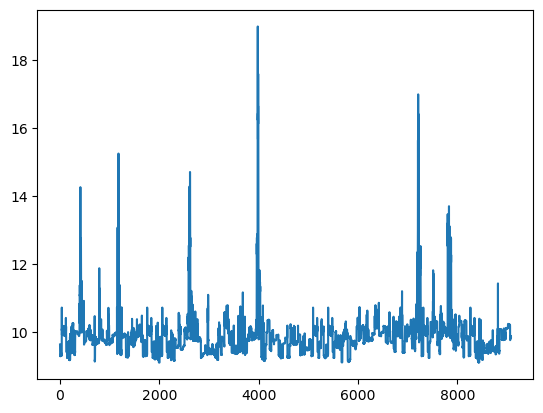

In [14]:
df_act.reset_index()['RESULTANT'].plot();

In [15]:
df_act.columns

Index(['ACTIVITY', 'X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9',
       'Y0', 'Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Z0', 'Z1',
       'Z2', 'Z3', 'Z4', 'Z5', 'Z6', 'Z7', 'Z8', 'Z9', 'XAVG', 'YAVG', 'ZAVG',
       'XPEAK', 'YPEAK', 'ZPEAK', 'XABSOLDEV', 'YABSOLDEV', 'ZABSOLDEV',
       'XSTANDDEV', 'YSTANDDEV', 'ZSTANDDEV', 'XVAR', 'YVAR', 'ZVAR', 'XMFCC0',
       'XMFCC1', 'XMFCC2', 'XMFCC3', 'XMFCC4', 'XMFCC5', 'XMFCC6', 'XMFCC7',
       'XMFCC8', 'XMFCC9', 'XMFCC10', 'XMFCC11', 'XMFCC12', 'YMFCC0', 'YMFCC1',
       'YMFCC2', 'YMFCC3', 'YMFCC4', 'YMFCC5', 'YMFCC6', 'YMFCC7', 'YMFCC8',
       'YMFCC9', 'YMFCC10', 'YMFCC11', 'YMFCC12', 'ZMFCC0', 'ZMFCC1', 'ZMFCC2',
       'ZMFCC3', 'ZMFCC4', 'ZMFCC5', 'ZMFCC6', 'ZMFCC7', 'ZMFCC8', 'ZMFCC9',
       'ZMFCC10', 'ZMFCC11', 'ZMFCC12', 'XYCOS', 'XZCOS', 'YZCOS', 'XYCOR',
       'XZCOR', 'YZCOR', 'RESULTANT', 'ID'],
      dtype='object')

In [16]:
df_act["ACTIVITY"].unique()

array(['F', 'G', 'O', 'P', 'Q', 'R', 'S'], dtype=object)

## Multivariate A-R Model

We can treat the learned characteristics of all the timeseries data observed to-date, as well as the other covariates observed at the same time step, as informative about the structure of the unrealised current state of the predictor. 


In [17]:
# df_eat_lim = df_eat[["ID", "ACTIVITY", "ZSTANDDEV", "RESULTANT"]]
# df_eat_lim["ZSTANDDEV_lag1"] = df_eat_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(1)
# df_eat_lim["RESULTANT_lag1"] = df_eat_lim.groupby(["ID", "ACTIVITY"])["RESULTANT"].shift(1)
# df_eat_lim["ZPEAK_avg"] = [avg_peak.loc[("Eat_avg", i), "ZPEAK"] for i in df_eat_lim["ID"]]
# df_eat_lim["ZSTANDDEV_avg"] = [avg_peak.loc[("Eat_avg", i), "ZSTANDDEV"] for i in df_eat_lim["ID"]]
# df_eat_lim["ZSTANDDEV_peak_avg"] = [avg_peak.loc[("Eat_peak", i), "ZSTANDDEV"] for i in df_eat_lim["ID"]]
# df_eat_lim["RESULTANT_avg"] = [avg_peak.loc[("Eat_avg", i), "RESULTANT"] for i in df_eat_lim["ID"]]
# df_eat_lim["RESULTANT_peak_avg"] = [avg_peak.loc[("Eat_peak", i), "RESULTANT"] for i in df_eat_lim["ID"]]
# df_eat_lim["ENTROPY_avg"] = [entropy.loc[("eat_entr_mean", i), 0] for i in df_eat_lim["ID"]]
# df_eat_lim["TOTALMIN"] = [total_min.loc[("Eat", i), "ACTIVITY"] for i in df_eat_lim["ID"]]
# df_eat_lim = df_eat_lim.dropna()

df_act_lim = df_act[["ID", "ACTIVITY", "ZSTANDDEV", "RESULTANT"]]
df_act_lim["ZSTANDDEV_lag1"] = df_act_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(1)
df_act_lim["ZSTANDDEV_lag2"] = df_act_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(2)
df_act_lim["ZSTANDDEV_lag3"] = df_act_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(3)
df_act_lim["RESULTANT_lag1"] = df_act_lim.groupby(["ID", "ACTIVITY"])["RESULTANT"].shift(1)
df_act_lim["RESULTANT_lag2"] = df_act_lim.groupby(["ID", "ACTIVITY"])["RESULTANT"].shift(2)
df_act_lim["RESULTANT_lag3"] = df_act_lim.groupby(["ID", "ACTIVITY"])["RESULTANT"].shift(3)
df_act_lim["ZPEAK_avg"] = [avg_peak.loc[("Eat_avg", i), "ZPEAK"] for i in df_act_lim["ID"]]
df_act_lim["ZSTANDDEV_avg"] = [avg_peak.loc[("Eat_avg", i), "ZSTANDDEV"] for i in df_act_lim["ID"]]
df_act_lim["ZSTANDDEV_peak_avg"] = [avg_peak.loc[("Eat_peak", i), "ZSTANDDEV"] for i in df_act_lim["ID"]]
df_act_lim["RESULTANT_avg"] = [avg_peak.loc[("Eat_avg", i), "RESULTANT"] for i in df_act_lim["ID"]]
df_act_lim["RESULTANT_peak_avg"] = [avg_peak.loc[("Eat_peak", i), "RESULTANT"] for i in df_act_lim["ID"]]
df_act_lim["ENTROPY_avg"] = [entropy.loc[("eat_entr_mean", i), 0] for i in df_act_lim["ID"]]
df_act_lim["TOTALMIN"] = [total_min.loc[("Eat", i), "ACTIVITY"] for i in df_act_lim["ID"]]
df_act_lim = df_act_lim.dropna()

id_indx, unique_ids = pd.factorize(df_act_lim["ID"])
act_indx, unique_acts = pd.factorize(df_act_lim["ACTIVITY"])
coords = {"ids": unique_ids, "acts": unique_acts, "obs": range(len(df_act_lim["RESULTANT"]))}

/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_53807/1729650824.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_act_lim["ZSTANDDEV_lag1"] = df_act_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(1)
/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_53807/1729650824.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_act_lim["ZSTANDDEV_lag2"] = df_act_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(2)
/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_53807/17296

In [18]:
with pm.Model(coords=coords) as model_ar3_pred:
    id_indx_data = pm.MutableData("id_indx_data", id_indx)
    act_indx_data = pm.MutableData("act_indx_data", act_indx)
    res_lag1_data = pm.MutableData("res_lag1_data", df_act_lim["RESULTANT_lag1"].values)
    res_lag2_data = pm.MutableData("res_lag2_data", df_act_lim["RESULTANT_lag2"].values)
    res_lag3_data = pm.MutableData("res_lag3_data", df_act_lim["RESULTANT_lag3"].values)
    zpeak_avg_data = pm.MutableData("zpeak_avg_data", df_act_lim["ZPEAK_avg"].values)
    zstanddev_avg_data = pm.MutableData("zstanddev_avg_data", df_act_lim["ZSTANDDEV_avg"].values)
    zstanddev_peak_avg_data = pm.MutableData("zstanddev_peak_avg_data", df_act_lim["ZSTANDDEV_peak_avg"].values)
    resultant_avg_data = pm.MutableData("resultant_avg_data", df_act_lim["RESULTANT_avg"].values)
    resultant_peak_avg_data = pm.MutableData("resultant_peak_avg_data", df_act_lim["RESULTANT_peak_avg"].values)
    entropy_avg_data = pm.MutableData("entropy_avg_data", df_act_lim["ENTROPY_avg"].values)
    totalmin_data = pm.MutableData("totalmin_data", df_act_lim["TOTALMIN"].values)
    observed = pm.MutableData("observed", df_act_lim["RESULTANT"].values)

    ## Level 1
    global_intercept = pm.Normal("global_intercept", 10, 2)
    global_sigma = pm.HalfStudentT("global_sigma", 1, 3)
    
    global_zpeak_avg_beta = pm.Normal("global_zpeak_avg_beta", 0, 1)
    global_zstanddev_avg_beta = pm.Normal("global_zstanddev_avg_beta", 0, 1)
    global_zstanddev_peak_avg_beta = pm.Normal("global_zstanddev_peak_avg_beta", 0, 1)
    global_resultant_avg_beta = pm.Normal("global_resultant_avg_beta", 0, 1)
    global_resultant_peak_avg_beta = pm.Normal("global_resultant_peak_avg_beta", 0, 1)
    global_entropy_avg_beta = pm.Normal("global_entropy_avg_beta", 0, 1)
    global_totalmin_beta = pm.Normal("global_totalmin_beta", 0, 1)
    
    global_res_lag1_beta = pm.Normal("global_res_lag1_beta", 0, 1)
    global_res_lag2_beta = pm.Normal("global_res_lag2_beta", 0, 1)
    global_res_lag3_beta = pm.Normal("global_res_lag3_beta", 0, 1)

    subject_intercept_sigma = pm.HalfNormal("subject_intercept_sigma", 2)
    activity_intercept_sigma = pm.HalfNormal("activity_intercept_sigma", 2)

    ## Level 2
    subject_intercept = pm.Normal("subject_intercept", 0, subject_intercept_sigma, dims="ids")
    activity_intercept = pm.Normal("activity_intercept", 0, activity_intercept_sigma, dims="acts")

    growth_model = pm.Deterministic(
        "growth_model",
        (global_intercept + subject_intercept[id_indx_data] + activity_intercept[act_indx_data])
        + global_zpeak_avg_beta * zpeak_avg_data
        + global_zstanddev_avg_beta * zstanddev_avg_data
        + global_zstanddev_peak_avg_beta * zstanddev_peak_avg_data
        + global_resultant_avg_beta * resultant_avg_data
        + global_resultant_peak_avg_beta * resultant_peak_avg_data
        + global_entropy_avg_beta * entropy_avg_data
        + global_totalmin_beta * totalmin_data
        + global_res_lag1_beta * res_lag1_data
        + global_res_lag2_beta * res_lag2_data
        + global_res_lag3_beta * res_lag3_data,
    )
    
    outcome = pm.Normal(
        "outcome", growth_model, global_sigma, observed = observed, dims = "obs"
    )
    
    idata_ar3_pred = pm.sample_prior_predictive()
    idata_ar3_pred.extend(
        pm.sample(random_seed=100, target_accept=0.95, idata_kwargs={"log_likelihood": True})
    )
    idata_ar3_pred.extend(pm.sample_posterior_predictive(idata_ar3_pred))

Sampling: [activity_intercept, activity_intercept_sigma, global_entropy_avg_beta, global_intercept, global_res_lag1_beta, global_res_lag2_beta, global_res_lag3_beta, global_resultant_avg_beta, global_resultant_peak_avg_beta, global_sigma, global_totalmin_beta, global_zpeak_avg_beta, global_zstanddev_avg_beta, global_zstanddev_peak_avg_beta, outcome, subject_intercept, subject_intercept_sigma]
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [global_intercept, global_sigma, global_zpeak_avg_beta, global_zstanddev_avg_beta, global_zstanddev_peak_avg_beta, global_resultant_avg_beta, global_resultant_peak_avg_beta, global_entropy_avg_beta, global_totalmin_beta, global_res_lag1_beta, global_res_lag2_beta, global_res_lag3_beta, subject_intercept_sigma, activity_intercept_sigma, subject_intercept, activity_intercept]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4480 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [outcome]


In [19]:
idata_ar3_pred.to_netcdf("models/idata_ar3_pred.nc")

'models/idata_ar3_pred.nc'

In [20]:
# idata_ar3_pred = az.from_netcdf("models/idata_ar3_pred.nc")

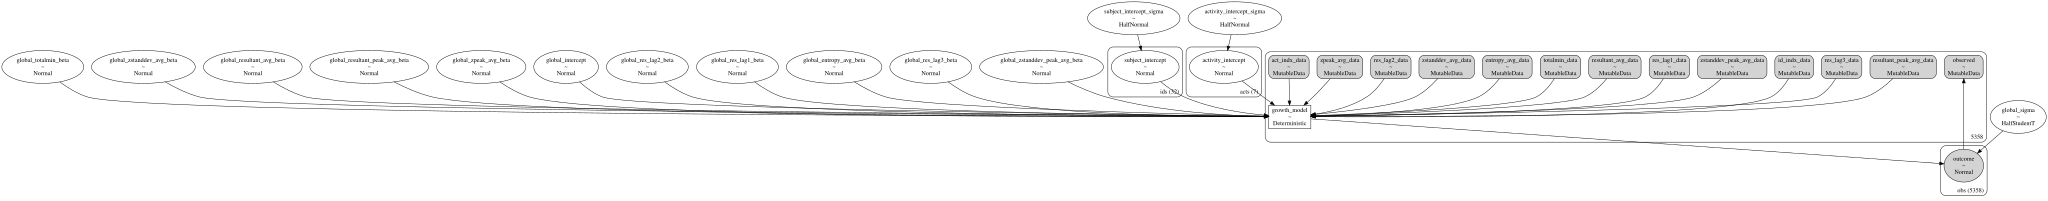

In [21]:
graph = pm.model_to_graphviz(model_ar3_pred)
graph.render("models/figure_ar3_pred", format = "png")
graph

In [22]:
idata_ar3_pred

Inference data with groups:
	> posterior
	> posterior_predictive
	> log_likelihood
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> constant_data

array([[<Axes: title={'center': 'global_intercept'}>,
        <Axes: title={'center': 'global_intercept'}, xlabel='Rank (all chains)'>],
       [<Axes: title={'center': 'global_zpeak_avg_beta'}>,
        <Axes: title={'center': 'global_zpeak_avg_beta'}, xlabel='Rank (all chains)'>],
       [<Axes: title={'center': 'global_zstanddev_avg_beta'}>,
        <Axes: title={'center': 'global_zstanddev_avg_beta'}, xlabel='Rank (all chains)'>],
       [<Axes: title={'center': 'global_zstanddev_peak_avg_beta'}>,
        <Axes: title={'center': 'global_zstanddev_peak_avg_beta'}, xlabel='Rank (all chains)'>],
       [<Axes: title={'center': 'global_resultant_avg_beta'}>,
        <Axes: title={'center': 'global_resultant_avg_beta'}, xlabel='Rank (all chains)'>],
       [<Axes: title={'center': 'global_resultant_peak_avg_beta'}>,
        <Axes: title={'center': 'global_resultant_peak_avg_beta'}, xlabel='Rank (all chains)'>],
       [<Axes: title={'center': 'global_entropy_avg_beta'}>,
        <Axes: 

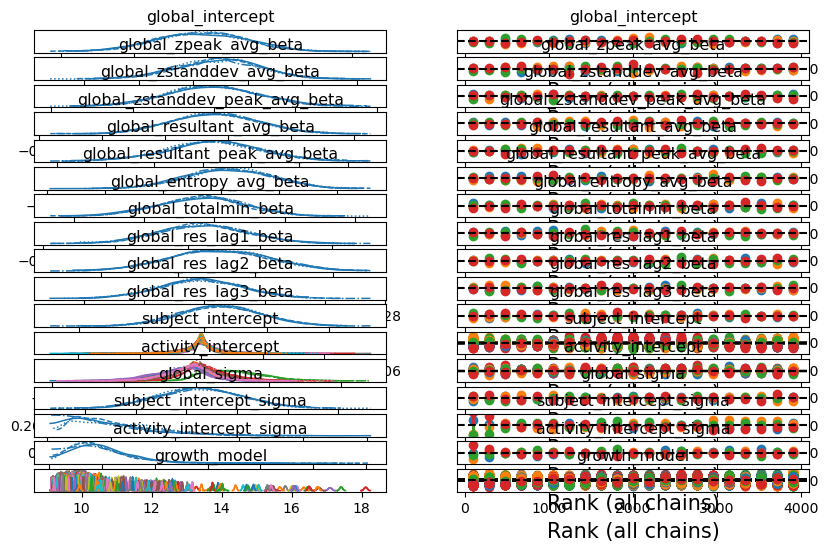

In [23]:
az.plot_trace(idata_ar3_pred, figsize=(10, 6), kind="rank_vlines")

In [24]:
az.summary(idata_ar3_pred)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
global_intercept,0.185,0.124,-0.034,0.430,0.002,0.002,2769.0,2185.0,1.0
global_zpeak_avg_beta,-0.001,0.001,-0.002,0.001,0.000,0.000,2594.0,2793.0,1.0
global_zstanddev_avg_beta,0.493,0.283,-0.049,1.016,0.006,0.004,2412.0,2898.0,1.0
global_zstanddev_peak_avg_beta,-0.010,0.034,-0.077,0.051,0.001,0.001,2521.0,2219.0,1.0
global_resultant_avg_beta,0.045,0.020,0.007,0.082,0.000,0.000,1850.0,2561.0,1.0
...,...,...,...,...,...,...,...,...,...
growth_model[5353],9.464,0.010,9.445,9.482,0.000,0.000,4159.0,3376.0,1.0
growth_model[5354],9.423,0.010,9.404,9.440,0.000,0.000,4123.0,3545.0,1.0
growth_model[5355],9.448,0.010,9.430,9.467,0.000,0.000,4267.0,3668.0,1.0
growth_model[5356],9.442,0.010,9.424,9.461,0.000,0.000,4110.0,3357.0,1.0


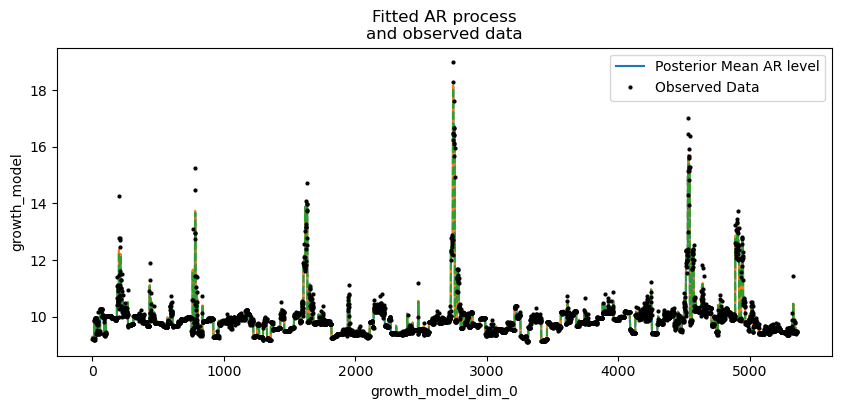

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
idata_ar3_pred.posterior.growth_model.mean(["chain", "draw"]).plot(ax=ax, label="Posterior Mean AR level")
(idata_ar3_pred.posterior.growth_model.mean(["chain", "draw"]) + idata_ar3_pred.posterior.growth_model.std(["chain", "draw"])).plot(ax=ax, ls = '--')
(idata_ar3_pred.posterior.growth_model.mean(["chain", "draw"]) - idata_ar3_pred.posterior.growth_model.std(["chain", "draw"])).plot(ax=ax, ls = '--')
ax.plot(df_act_lim.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
ax.legend()
ax.set_title("Fitted AR process\nand observed data");

In [ ]:
print(df_act_lim.loc[df_act_lim["ID"] == 1601, :])

for i in df_act_lim["ID"].unique():
    id_df = df_act_lim.loc[df_act_lim["ID"] == i, :]
    for a in id_df["ACTIVITY"].unique():
        plot_df = id_df.loc[id_df["ACTIVITY"] == a, :]
        if i == 1601:
            print(plot_df.shape)
            # print(np.where(df_eat_lim["ID"] == i and df_eat_lim["ACTIVITY"]) == a)

### Predictions

 - Forecast from the  posterior given the observations so far

In [ ]:
n = test_df["RESULTANT"].shape[0]

id_indx_test, unique_ids_test = pd.factorize(test_df["ACTIVITY"])

with model:
    model.add_coords({"obs_id_fut": range(n)})

    pm.set_data(
        {
            "id_indx"            : id_indx_test,
            "res_lag1_data"      : test_df["RESULTANT_lag1"].values,
            "zpeak_data"         : test_df["ZPEAK"].values,
            "zpeak_lag1_data"    : test_df["ZPEAK_lag1"].values,
            "zstanddev_data"     : test_df["ZSTANDDEV"].values,
            "zstanddev_lag1_data": test_df["ZSTANDDEV_lag1"].values,
            "observed"           : np.zeros(n),
        }
    )

    outcome_future = pm.Normal("outcome_future", mu=growth_model, sigma=global_sigma, dims="obs_id_fut")

    idata_m2_preds = pm.sample_posterior_predictive(idata_m2, var_names=["outcome_future"], random_seed=100,
                                                    predictions=True)


In [ ]:
idata_m2_preds

In [ ]:
plt.plot(np.concatenate([idata_m2.posterior.growth_model.mean(axis=(0, 1)),
                         idata_m2_preds.predictions["outcome_future"].mean(axis=(0, 1))]))
plt.plot(train_df.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
plt.axvline(x=len(train_df), color='r', linestyle='--')
plt.xlim((5000, len(train_df) + len(test_df)))